# Model development: Seoul bicycle demand

**This notebook is the project's core development workflow.** Run it from top to bottom for data analysis, model comparison, tuning, and final evaluation. Tables and charts are computed here from the fixed CSV by calling the same functions as `bike-train`. Only data download and `uv sync --locked --python 3.11` are prerequisites; prior model/report files are not required.

Shared data.py and modeling.py functions supply the calculations; train.py is the secondary batch retraining/export entry. The workflow follows the predefined feature groups, validation weeks, parameter grids, and selection rule. It reproduces the current experiment rather than a historical record of every earlier exploratory attempt. [Project guide](README.md).


In [1]:
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import display
from threadpoolctl import threadpool_limits
from seoul_bike.data import (
    ROOT, TARGET, WEEKS, TEST_START, TEST_END, load_data, build_features,
    feature_columns, sample_masks, validation_splits, baselines,
)
from seoul_bike.modeling import (
    BASE, evaluate, tuning_grid, select_candidate, make_model,
    scores, prediction_frame, diagnostics, feature_group_importance,
)

%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

root = ROOT
figures = root / "reports/figures"
figures.mkdir(parents=True, exist_ok=True)

raw = load_data()
dev, test = sample_masks(raw)
development = raw.loc[dev]
family_labels = {
    "ridge": "Ridge", "forest": "Random forest", "boosting": "Gradient boosting",
}
rule_labels = {
    "yesterday": "Yesterday, same hour",
    "last_week": "Last week, same hour",
    "weekly_mean": "Previous 1-4 weeks, matching hour",
}
print("Python:", sys.executable)
print("CSV: 8,760 rows, 14 columns; loaded:", raw.shape, "plus a time index.")
print("Coverage:", raw.index.min(), "through", raw.index.max())
display(raw.head(3))

Python: C:\Users\yanji\Projects\seoul-bike-demand-prediction\.venv\Scripts\python.exe
CSV: 8,760 rows, 14 columns; loaded: (8760, 13) plus a time index.
Coverage: 2017-12-01 00:00:00+09:00 through 2018-11-30 23:00:00+09:00


,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
target_start,,,,,,,,,,,,,
2017-12-01 00:00:00+09:00,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2017-12-01 01:00:00+09:00,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2017-12-01 02:00:00+09:00,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes


## 1. Check data quality and choose the analysis population

**Use normal-operation development targets for exploratory rental analysis, and retain all source hours for historical inputs.** Shutdown hours are excluded as target labels. The 17 suspicious humidity zeros become missing values only in feature construction; other weather zeros remain recorded values.

The source checks below examine timestamps and field completeness. Rental distributions and subsequent exploratory plots use development targets; final-test rental labels are scored after model selection.


In [2]:
quality = pd.Series({
    "Source hours": len(raw),
    "Duplicate timestamps": int(raw.index.duplicated().sum()),
    "Raw null cells": int(raw.isna().sum().sum()),
    "Shutdown hours": int(raw["Functioning Day"].eq("No").sum()),
    "Suspicious zero humidity": int(raw["Humidity(%)"].eq(0).sum()),
    "Development targets": int(dev.sum()),
    "Reserved final-test targets": int(test.sum()),
}, name="Count")
display(quality.to_frame())
display(development.describe().T.round(2))

,Count
Source hours,8760
Duplicate timestamps,0
Raw null cells,0
Shutdown hours,295
Suspicious zero humidity,17
Development targets,7910
Reserved final-test targets,384


,count,mean,std,min,25%,50%,75%,max
Rented Bike Count,7910.0,740.02,655.38,2.0,212.00,545.00,1113.75,3556.00
Hour,7910.0,11.51,6.92,0.0,6.00,12.00,17.75,23.00
Temperature(°C),7910.0,13.41,12.21,-17.8,3.72,15.00,23.20,39.40
Humidity(%),7910.0,58.42,20.35,0.0,43.00,57.00,74.00,98.00
Wind speed (m/s),7910.0,1.74,1.04,0.0,1.00,1.50,2.40,7.40
Visibility (10m),7910.0,1444.01,605.19,27.0,953.50,1707.00,2000.00,2000.00
Dew point temperature(°C),7910.0,4.62,13.32,-30.6,-4.20,6.20,15.70,27.20
Solar Radiation (MJ/m2),7910.0,0.59,0.89,0.0,0.00,0.02,0.96,3.52
Rainfall(mm),7910.0,0.16,1.16,0.0,0.00,0.00,0.00,35.00
Snowfall (cm),7910.0,0.07,0.38,0.0,0.00,0.00,0.00,5.10


## 2. Examine time patterns and weather associations

**Compare weekday/weekend hourly profiles, monthly levels, and observed weather groups before fitting a model.** All plots below use development targets. Differences describe associations among recorded conditions; weather enters forecasting through completed historical observations.

The monthly chart covers the development period, so November ends at the training cutoff. Rainfall groups use the source's recorded zero/positive distinction.


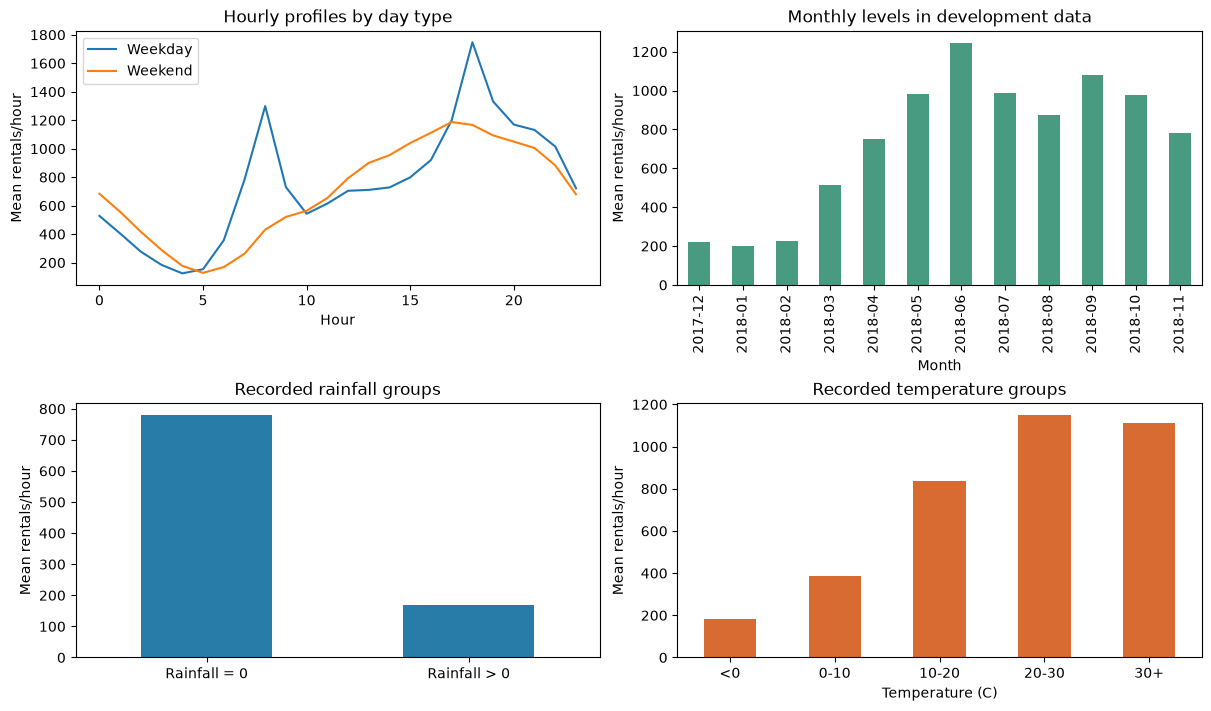

,Target hours,Mean rentals,Median rentals
Rainfall(mm),,,
Rainfall = 0,7406,778.93,600.0
Rainfall > 0,504,168.27,68.0


In [3]:
hourly = development.groupby([
    development.index.hour, development.index.day_of_week >= 5,
])[TARGET].mean().unstack()
hourly.columns = ["Weekday", "Weekend"]
monthly = development.groupby(development.index.strftime("%Y-%m"))[TARGET].mean()
rain_group = development["Rainfall(mm)"].gt(0).map({
    False: "Rainfall = 0", True: "Rainfall > 0",
})
rain_summary = development.groupby(rain_group)[TARGET].agg(["size", "mean", "median"])
temperature_group = pd.cut(
    development["Temperature(°C)"], [-np.inf, 0, 10, 20, 30, np.inf],
    right=False, labels=["<0", "0-10", "10-20", "20-30", "30+"],
)
temperature_mean = development.groupby(
    temperature_group, observed=True,
)[TARGET].mean()

fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
hourly.plot(ax=axes[0, 0])
axes[0, 0].set(title="Hourly profiles by day type", xlabel="Hour")
monthly.plot.bar(ax=axes[0, 1], color="#489b81")
axes[0, 1].set(title="Monthly levels in development data", xlabel="Month")
rain_summary["mean"].plot.bar(ax=axes[1, 0], color="#277da8", rot=0)
axes[1, 0].set(title="Recorded rainfall groups", xlabel="")
temperature_mean.plot.bar(ax=axes[1, 1], color="#d76b31", rot=0)
axes[1, 1].set(title="Recorded temperature groups", xlabel="Temperature (C)")
for ax in axes.flat:
    ax.set_ylabel("Mean rentals/hour")
plt.show()
display(rain_summary.rename(columns={
    "size": "Target hours", "mean": "Mean rentals", "median": "Median rentals",
}).round(2))

## 3. Build inputs and separate development from final test

**A 17:00 issue predicts 18:00–19:00 using observations completed through 17:00.** The latest source row starts at 16:00. Target dates and holidays are known; historical rental/weather records start no later than S−2 hours.

| Target category | Hours | Handling |
| --- | ---: | --- |
| Insufficient early history | 169 | Exclude targets lacking all 168 rental-history records |
| Non-operating | 295 | Exclude shutdown zeros as normal-operation target labels |
| Development | 7,910 | Compare configurations and fit the final choice |
| Training/test boundary | 2 | Respect label availability and reserve fitting time |
| Final test | 384 | Score the selected model on November 15–30 |

The 168-record history covers S−169 through S−2. Historical counts currently retain shutdown zeros, which lower their means, alongside selected past operating-status inputs. At the final-test boundary, the last training label is available at November 14 22:00; the first prediction is issued at 23:00 after one hour reserved for fitting.

Weather groups are nested: W1 uses past values; W2 adds observed changes; W3 adds statistics over consecutive 3/6/24/48-hour periods. Every candidate also uses target-time information, rental history, and past operating status.


In [4]:
features = build_features(raw)
baseline = baselines(raw)
splits = list(validation_splits(raw))
validation_targets = np.logical_or.reduce([val for _, val in splits])
assert not np.any(dev & test)
assert not np.any(validation_targets & test)
assert int(validation_targets.sum()) == sum(int(v.sum()) for _, v in splits)

example = pd.Timestamp("2018-07-15 18:00", tz="Asia/Seoul")
example_labels = {
    "hour": "Target hour",
    "weekday": "Weekday (Monday=0)",
    "count_lag2": "Rentals: latest completed source hour",
    "count_lag24": "Rentals: yesterday's matching hour",
    "count_mean168": "Rentals: mean of 168 consecutive completed hours",
    "w1_temp_lag2": "Temperature: latest completed source hour",
    "w2_temp_delta3": "Temperature: latest minus three hours earlier",
    "w3_temp_mean6": "W3 candidate: mean of six completed temperature records",
}
display(features.loc[[example], list(example_labels)].rename(
    columns=example_labels,
).T)
display(pd.Series({
    group: len(feature_columns(features, group)) for group in ("W1", "W2", "W3")
}, name="Input columns").to_frame())

target_start,2018-07-15 18:00:00+09:00
Target hour,18.000000
Weekday (Monday=0),6.000000
Rentals: latest completed source hour,1125.000000
Rentals: yesterday's matching hour,1624.000000
Rentals: mean of 168 consecutive completed hours,964.797619
Temperature: latest completed source hour,32.800000
Temperature: latest minus three hours earlier,1.400000
W3 candidate: mean of six completed temperature records,31.383333


,Input columns
W1,64
W2,88
W3,192


## 4. Why use three validation rounds?

**Validation is spread across all 12 observed months to improve coverage, with three fits per candidate.** Every round holds out one week from each season. Round 1 uses each season's first month, round 2 its middle month, and round 3 its last month.

This rotates the evaluation weeks and reduces dependence on one choice of weeks, while most development targets still train in each round. Three rounds are a practical coverage/computation tradeoff; more rounds would cost more fits. All rounds use the same model architecture across seasons. A comparison fit uses 6,562/6,593/6,613 training targets after validation and temporary exclusions; final fitting restores all 7,910 development targets. Across rounds, validation contains 1,841 targets from 12 selected weeks; the 384 final-test targets remain reserved.

Training may include months later than a held-out week. These comparisons evaluate performance across this observed year; the later final test evaluates the frozen choice using only earlier training labels. Each round also excludes training targets whose count inputs contain its validation answers, plus a fixed one-day gap before each validation week.


,Training targets,Validation targets,Temporarily excluded
Round 1,6562,624,724
Round 2,6593,593,724
Round 3,6613,624,673


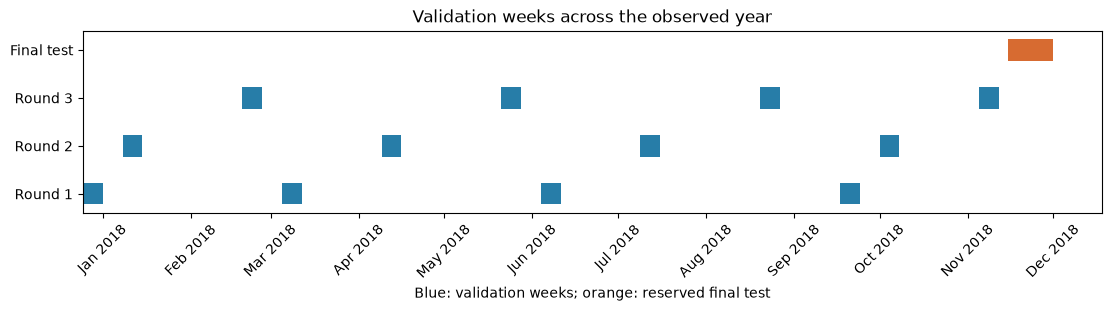

In [5]:
round_counts = pd.DataFrame({
    "Training targets": [int(t.sum()) for t, _ in splits],
    "Validation targets": [int(v.sum()) for _, v in splits],
    "Temporarily excluded": [int((dev & ~t & ~v).sum()) for t, v in splits],
}, index=["Round 1", "Round 2", "Round 3"])
display(round_counts)

fig, ax = plt.subplots(figsize=(11, 3), constrained_layout=True)
for number, week_starts in enumerate(WEEKS, 1):
    for start in week_starts:
        ax.barh(number, 7, left=mdates.date2num(pd.Timestamp(start)),
                height=0.45, color="#277da8")
ax.barh(4, (TEST_END - TEST_START).days,
        left=mdates.date2num(TEST_START.tz_localize(None)),
        height=0.45, color="#d76b31")
ax.set_yticks([1, 2, 3, 4], ["Round 1", "Round 2", "Round 3", "Final test"])
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set(title="Validation weeks across the observed year",
       xlabel="Blue: validation weeks; orange: reserved final test")
ax.tick_params(axis="x", rotation=45)
plt.show()

## 5. Train initial candidates and compare with simple rules

**First fit nine candidates: three model families crossed with three weather groups.** Ridge learns linear relationships, random forest averages trees, and gradient boosting adds trees that correct earlier errors. Every candidate uses the same three validation rounds.

The rules below provide a reference without fitting: yesterday's matching hour, last week's matching hour, and the mean of available matching hours in the previous one to four weeks. MAE is average absolute error in rentals/hour; lower is better. Candidate training calls `evaluate()`, which fits preprocessing and a fresh model separately in each round.


In [6]:
rule_validation = pd.DataFrame({
    label: scores(raw.loc[validation_targets, TARGET],
                  baseline.loc[validation_targets, name])
    for name, label in rule_labels.items()
}).T
display(rule_validation.rename(columns={
    "mae": "Validation MAE", "rmse": "Validation RMSE", "bias": "Mean bias",
}).round(2))

,Validation MAE,Validation RMSE,Mean bias
"Yesterday, same hour",330.51,567.44,-87.94
"Last week, same hour",282.49,493.93,-37.06
"Previous 1-4 weeks, matching hour",271.07,421.38,-36.19


In [7]:
rows, predictions = [], {}
with threadpool_limits(limits=2):
    for family, params in BASE.items():
        for group in ("W1", "W2", "W3"):
            identifier = f"c{len(rows) + 1:02d}"
            row, predicted = evaluate(
                raw, features, baseline, splits, family, group,
                params, "initial", identifier,
            )
            rows.append(row)
            predictions[identifier] = predicted

initial_results = pd.DataFrame(rows)
initial_best = initial_results.sort_values("mae").drop_duplicates("family")
display(initial_best[["family", "features", "params", "mae"]].rename(columns={
    "family": "Model family", "features": "Weather group",
    "params": "Initial settings", "mae": "Validation MAE",
}).reset_index(drop=True))

c01: ridge    W1 MAE=170.52 {'alpha': 1.0}


c02: ridge    W2 MAE=171.08 {'alpha': 1.0}


c03: ridge    W3 MAE=204.20 {'alpha': 1.0}


c04: forest   W1 MAE=139.78 {'max_depth': 16, 'min_samples_leaf': 10}


c05: forest   W2 MAE=139.23 {'max_depth': 16, 'min_samples_leaf': 10}


c06: forest   W3 MAE=142.28 {'max_depth': 16, 'min_samples_leaf': 10}


c07: boosting W1 MAE=126.62 {'max_leaf_nodes': 15, 'l2_regularization': 10.0}


c08: boosting W2 MAE=126.26 {'max_leaf_nodes': 15, 'l2_regularization': 10.0}


c09: boosting W3 MAE=131.55 {'max_leaf_nodes': 15, 'l2_regularization': 10.0}


,Model family,Weather group,Initial settings,Validation MAE
0,boosting,W2,"{""l2_regularization"": 10.0, ""max_leaf_nodes"": 15}",126.260567
1,forest,W2,"{""max_depth"": 16, ""min_samples_leaf"": 10}",139.226800
2,ridge,W1,"{""alpha"": 1.0}",170.516379


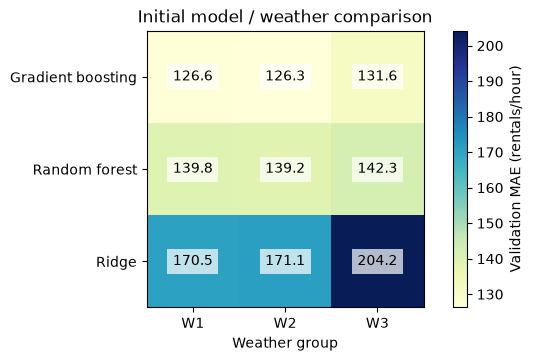

In [8]:
initial_matrix = initial_results.pivot(
    index="family", columns="features", values="mae",
)
fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
chart = ax.imshow(initial_matrix, cmap="YlGnBu")
ax.set_xticks(range(len(initial_matrix.columns)), initial_matrix.columns)
ax.set_yticks(range(len(initial_matrix.index)),
              [family_labels[name] for name in initial_matrix.index])
for i in range(len(initial_matrix.index)):
    for j in range(len(initial_matrix.columns)):
        ax.text(j, i, f"{initial_matrix.iloc[i, j]:.1f}",
                ha="center", va="center", color="black",
                bbox={"facecolor": "white", "alpha": 0.7, "edgecolor": "none"})
ax.set(title="Initial model / weather comparison", xlabel="Weather group")
fig.colorbar(chart, ax=ax, label="Validation MAE (rentals/hour)")
plt.show()

## 6. Tune the two strongest model families

**Keep each selected family's best initial weather group fixed, and compare its predefined parameter settings on the same validation targets.** The choice of families uses initial validation MAE. Each additional setting is fitted three times; final-test errors do not enter tuning.

For random forest, the search varies tree depth (`max_depth`) and minimum samples per leaf (`min_samples_leaf`). For gradient boosting, it varies maximum leaves (`max_leaf_nodes`) and L2 regularization strength (`l2_regularization`). The actual grids come from `tuning_grid()`; the table records which families are selected and how many new settings will run. An existing initial setting is reused rather than fitted twice.


,Family,Weather group,New parameter settings,Parameters varied
0,Gradient boosting,W2,8,"max_leaf_nodes, l2_regularization"
1,Random forest,W2,5,"max_depth, min_samples_leaf"


c10: boosting W2 MAE=142.41 {'max_leaf_nodes': 7, 'l2_regularization': 1.0}


c11: boosting W2 MAE=141.68 {'max_leaf_nodes': 7, 'l2_regularization': 10.0}


c12: boosting W2 MAE=144.86 {'max_leaf_nodes': 7, 'l2_regularization': 30.0}


c13: boosting W2 MAE=125.54 {'max_leaf_nodes': 15, 'l2_regularization': 1.0}


c14: boosting W2 MAE=127.30 {'max_leaf_nodes': 15, 'l2_regularization': 30.0}


... (5 outputs left out)

c20: forest   W2 MAE=147.49 {'max_depth': 10, 'min_samples_leaf': 25}


c21: forest   W2 MAE=135.20 {'max_depth': 16, 'min_samples_leaf': 3}


c22: forest   W2 MAE=147.16 {'max_depth': 16, 'min_samples_leaf': 25}


,Initial best MAE,Best evaluated MAE,Reduction (%)
Gradient boosting,126.26,121.32,3.91
Random forest,139.23,135.20,2.89


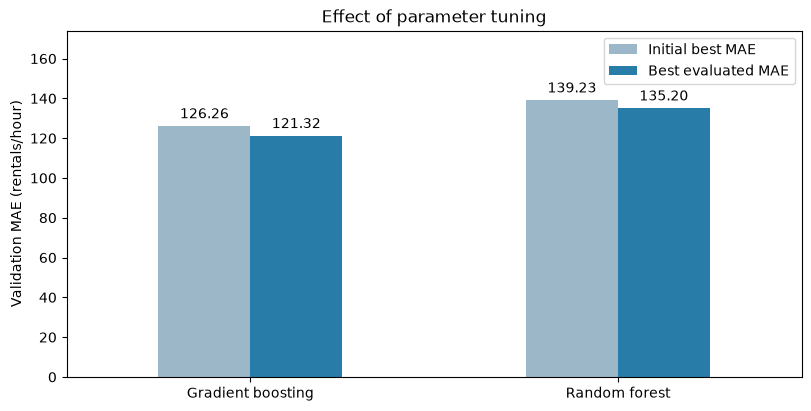

In [9]:
tuning_families = initial_best.head(2)
plan = []
for candidate in tuning_families.itertuples():
    settings = [p for p in tuning_grid(candidate.family)
                if p != BASE[candidate.family]]
    plan.append({
        "Family": family_labels[candidate.family],
        "Weather group": candidate.features,
        "New parameter settings": len(settings),
        "Parameters varied": ", ".join(BASE[candidate.family]),
    })
display(pd.DataFrame(plan))

with threadpool_limits(limits=2):
    for candidate in tuning_families.itertuples():
        for params in tuning_grid(candidate.family):
            if params == BASE[candidate.family]:
                continue
            identifier = f"c{len(rows) + 1:02d}"
            row, predicted = evaluate(
                raw, features, baseline, splits,
                candidate.family, candidate.features,
                params, "tuning", identifier,
            )
            rows.append(row)
            predictions[identifier] = predicted

comparison = pd.DataFrame(rows)
best_after = comparison.sort_values("mae").drop_duplicates("family")
before_after = initial_best.set_index("family")[["mae"]].rename(
    columns={"mae": "Initial best MAE"},
).join(best_after.set_index("family")["mae"].rename("Best evaluated MAE"))
before_after = before_after.loc[tuning_families["family"]].copy()
before_after["Reduction (%)"] = (
    1 - before_after["Best evaluated MAE"] / before_after["Initial best MAE"]
) * 100
before_after.index = [family_labels[name] for name in before_after.index]
display(before_after.round(2))

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
before_after[["Initial best MAE", "Best evaluated MAE"]].plot.bar(
    ax=ax, color=["#9cb7c7", "#277da8"], rot=0,
)
ax.set(title="Effect of parameter tuning", ylabel="Validation MAE (rentals/hour)",
       xlabel="", ylim=(0, before_after["Initial best MAE"].max() * 1.25))
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)
fig.savefig(figures / "tuning_comparison.png", dpi=150)
plt.show()

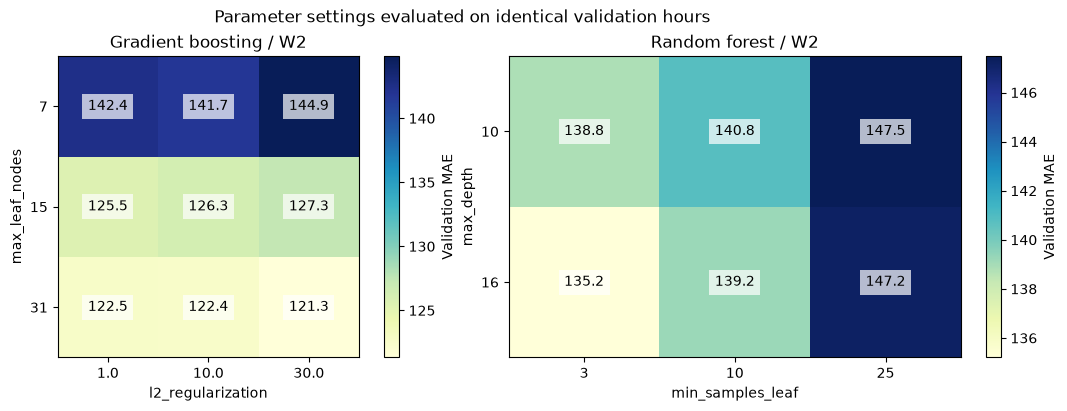

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, candidate in zip(axes, tuning_families.itertuples()):
    trials = comparison.loc[
        comparison["family"].eq(candidate.family)
        & comparison["features"].eq(candidate.features)
    ].reset_index(drop=True)
    parameter_values = pd.json_normalize(trials["params"].map(json.loads))
    parameter_values["MAE"] = trials["mae"]
    names = list(BASE[candidate.family])
    if len(names) == 1:
        parameter_values.plot(
            x=names[0], y="MAE", marker="o", logx=True, ax=ax, legend=False,
        )
        ax.set_ylabel("Validation MAE (rentals/hour)")
    else:
        vertical, horizontal = names
        matrix = parameter_values.pivot(
            index=vertical, columns=horizontal, values="MAE",
        )
        chart = ax.imshow(matrix, cmap="YlGnBu")
        ax.set_xticks(range(len(matrix.columns)), matrix.columns)
        ax.set_yticks(range(len(matrix.index)), matrix.index)
        ax.set(xlabel=horizontal, ylabel=vertical)
        for i in range(len(matrix.index)):
            for j in range(len(matrix.columns)):
                ax.text(j, i, f"{matrix.iloc[i, j]:.1f}",
                        ha="center", va="center", color="black",
                        bbox={"facecolor": "white", "alpha": 0.7,
                              "edgecolor": "none"})
        fig.colorbar(chart, ax=ax, label="Validation MAE")
    ax.set_title(f"{family_labels[candidate.family]} / {candidate.features}")
fig.suptitle("Parameter settings evaluated on identical validation hours")
fig.savefig(figures / "tuning_parameters.png", dpi=150)
plt.show()

## 7. Select and freeze one configuration

**Choose the final configuration using development validation only.** `select_candidate()` keeps candidates within 1% of the lowest MAE, then prefers the lowest worst-season error relative to the last-week rule, smaller model size, and shorter measured prediction time.

The selected candidate's validation predictions below were generated during its three fits. Seasonal results show how errors differ across the observed year. Once this configuration is selected, the next section fits it on all development targets and evaluates the reserved test.


Selected candidate: c17
Model: Gradient boosting / W2
Parameters: {'l2_regularization': 30.0, 'max_leaf_nodes': 31}
Validation MAE: 121.318
Configurations / validation fits: 22 / 66


,Validation MAE,Validation RMSE,Mean bias
"Yesterday, same hour",330.51,567.44,-87.94
"Last week, same hour",282.49,493.93,-37.06
"Previous 1-4 weeks, matching hour",271.07,421.38,-36.19
Selected model,121.32,207.64,4.64


,Validation MAE,Target hours,Distinct dates
Autumn,150.73,353.0,15.0
Spring,125.96,480.0,20.0
Summer,175.31,504.0,21.0
Winter,42.31,504.0,21.0


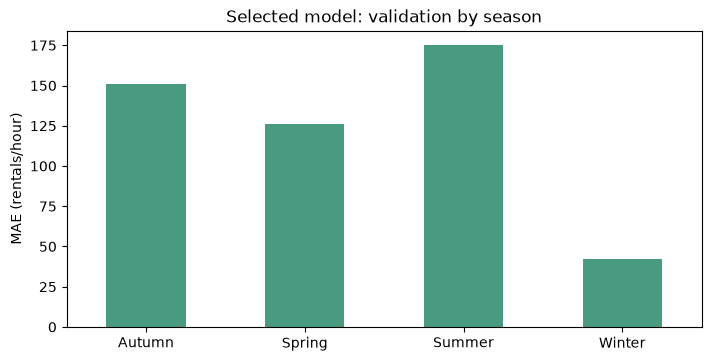

In [11]:
chosen = select_candidate(comparison)
comparison["selected"] = comparison["id"].eq(chosen["id"])
validation_predictions = predictions[chosen["id"]]
validation_diagnostics = diagnostics(validation_predictions)
print("Selected candidate:", chosen["id"])
print("Model:", family_labels[chosen["family"]], "/", chosen["features"])
print("Parameters:", json.loads(chosen["params"]))
print("Validation MAE:", round(chosen["mae"], 3))
print("Configurations / validation fits:", len(comparison), "/", len(comparison) * 3)

validation_summary = rule_validation.copy()
validation_summary.loc["Selected model"] = validation_diagnostics["overall"]
display(validation_summary.rename(columns={
    "mae": "Validation MAE", "rmse": "Validation RMSE", "bias": "Mean bias",
}).round(2))
season_scores = pd.DataFrame(validation_diagnostics["season"]).T
display(season_scores[["mae", "hours", "dates"]].rename(columns={
    "mae": "Validation MAE", "hours": "Target hours", "dates": "Distinct dates",
}).round(2))

fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
season_scores["mae"].plot.bar(ax=ax, color="#489b81", rot=0)
ax.set(title="Selected model: validation by season",
       ylabel="MAE (rentals/hour)", xlabel="")
plt.show()

### 7.1 Which input groups does the selected model use?

**Scramble one group of inputs and measure how much validation error increases.** For example, rearrange recent rental histories between hours within a held-out week while keeping actual answers fixed. A larger increase indicates that the fitted model relies more on that group.

The shared function refits the selected configuration on each of the same three training subsets, then makes five reproducible shuffles per group within each validation week. Related columns move together: known target time, rental history, weather history, and past operating status. The table combines rounds in proportion to their validation-hour counts; the error bars show variation across shuffles.

This diagnostic uses development validation only and does not change the selected inputs or settings. It measures model reliance, not causal effects or percentages of explained demand. Groups can substitute for one another, and scrambling can create unusual combinations. See the [method and correlation limits](https://scikit-learn.org/stable/modules/permutation_importance.html).


,Input group,Validation MAE increase,Shuffle standard deviation
0,Rental history,288.57,3.33
1,Weather history,75.68,2.59
2,Known target time,59.54,1.81
3,Past operating status,0.00,0.00


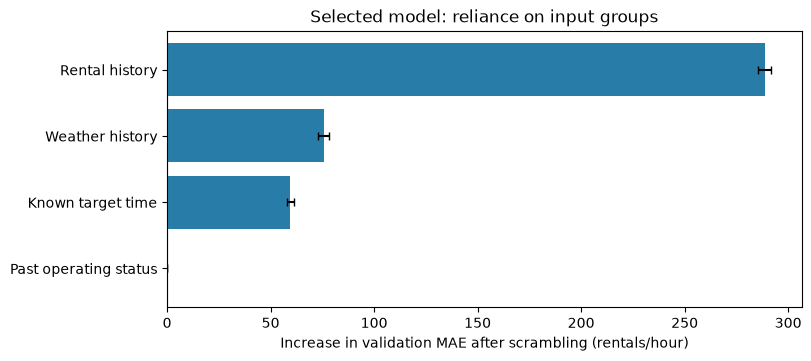

In [12]:
with threadpool_limits(limits=2):
    importance = feature_group_importance(
        raw, features, splits, chosen["family"], chosen["features"],
        json.loads(chosen["params"]),
    )
display(importance.rename(columns={
    "group": "Input group", "mae_increase": "Validation MAE increase",
    "shuffle_std": "Shuffle standard deviation",
}).round(2))
shown = importance.sort_values("mae_increase")
fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.barh(shown["group"], shown["mae_increase"],
        xerr=shown["shuffle_std"], color="#277da8", capsize=3)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(title="Selected model: reliance on input groups",
       xlabel="Increase in validation MAE after scrambling (rentals/hour)")
fig.savefig(figures / "feature_importance.png", dpi=150)
plt.show()


## 8. Fit once on development targets and evaluate final-test error

**Fit the frozen configuration on all 7,910 development targets, then predict the 384 later test targets.** The code below trains a new final model. Each test input uses only observations completed by its own issue time; model parameters remain fixed.

MAE measures typical absolute count error, RMSE emphasizes large errors, and mean bias is prediction minus actual. This regression task is evaluated in rentals/hour. The test evidence covers November 15–30; it is used to assess the selected model.


In [13]:
columns = feature_columns(features, chosen["features"])
parameters = json.loads(chosen["params"])
with threadpool_limits(limits=2):
    final_model = make_model(chosen["family"], columns, parameters)
    final_model.fit(features.loc[dev, columns], raw.loc[dev, TARGET])
    test_prediction = np.maximum(
        0, final_model.predict(features.loc[test, columns]),
    )
test_predictions = prediction_frame(
    raw, test, test_prediction, baseline,
    raw.loc[dev, TARGET].quantile(0.9), 0,
)
test_diagnostics = diagnostics(test_predictions)
test_scores = pd.DataFrame({
    "Selected model": test_diagnostics["overall"],
    **{rule_labels[name]: values
       for name, values in test_diagnostics["baselines"].items()},
}).T
display(test_scores.rename(columns={
    "mae": "Test MAE", "rmse": "Test RMSE", "bias": "Mean prediction - actual",
}).round(2))
gain = 100 * (
    1 - test_diagnostics["overall"]["mae"]
    / test_diagnostics["baselines"]["weekly_mean"]["mae"]
)
print(f"Test MAE reduction versus matching-hour weekly mean: {gain:.2f}%")

,Test MAE,Test RMSE,Mean prediction - actual
Selected model,85.25,129.66,-20.11
"Yesterday, same hour",143.44,255.30,16.69
"Last week, same hour",230.05,390.83,-3.50
"Previous 1-4 weeks, matching hour",128.19,178.09,45.02


Test MAE reduction versus matching-hour weekly mean: 33.50%


### 8.1 Practical reference value and relative errors

**Compare each prediction with actual volume and with the matching-hour weekly-mean rule to assess reference value for normal-operation hours.** A relative error is the absolute count error divided by the actual count for that hour. The table averages these percentages and counts hours within a 20% error band.

The 20% band is a descriptive reporting choice; configuration selection still uses validation MAE. The curve shows reporting thresholds from 0% to 100%, always counting all 384 test hours. The volume groups below are post-prediction diagnostics, not model inputs or product demand classes.

Use the grouped results to identify low-count limitations alongside the overall comparison. Benchmark evidence here covers past-count rules. Assessing a weather-only matching rule would require a separately defined comparison under the same observation-time cutoff.


,Mean absolute error (rentals/hour),Mean hourly percentage error (%),Hours within 20% of actual (%)
Selected model,85.25,21.33,77.60
Matching-hour weekly mean,128.19,35.78,61.46


Mean actual rentals/hour: 674.93
Model closer than weekly mean: 239/384 hours (62.24%)


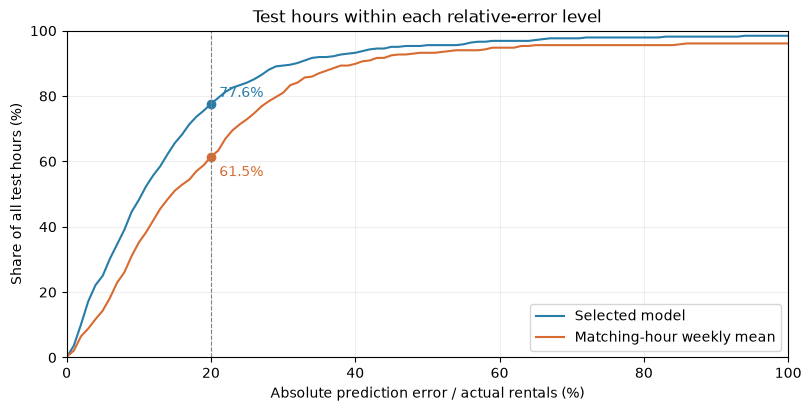

,Hours,Mean actual,Model MAE,Rule MAE,Model closer (%)
Actual rentals/hour,,,,,
<100,13,73.62,95.43,140.38,30.77
100-499,121,284.07,49.86,94.51,61.16
500-999,186,747.28,76.19,129.21,65.59
1000+,64,1325.73,176.39,186.43,60.94


In [14]:
actual_counts = test_predictions["actual"]
assert actual_counts.gt(0).all(), "Percentage errors require positive actual counts."
model_errors = (test_predictions["prediction"] - actual_counts).abs()
rule_errors = (test_predictions["weekly_mean"] - actual_counts).abs()
model_relative_errors = model_errors / actual_counts
rule_relative_errors = rule_errors / actual_counts

performance = pd.DataFrame({
    "Selected model": {
        "Mean absolute error (rentals/hour)": model_errors.mean(),
        "Mean hourly percentage error (%)": model_relative_errors.mean() * 100,
        "Hours within 20% of actual (%)": model_relative_errors.le(0.2).mean() * 100,
    },
    "Matching-hour weekly mean": {
        "Mean absolute error (rentals/hour)": rule_errors.mean(),
        "Mean hourly percentage error (%)": rule_relative_errors.mean() * 100,
        "Hours within 20% of actual (%)": rule_relative_errors.le(0.2).mean() * 100,
    },
}).T
display(performance.round(2))
closer_hours = int(model_errors.lt(rule_errors).sum())
print(f"Mean actual rentals/hour: {actual_counts.mean():.2f}")
print(
    f"Model closer than weekly mean: {closer_hours}/{len(actual_counts)} hours "
    f"({100 * closer_hours / len(actual_counts):.2f}%)"
)

thresholds = np.arange(0, 101)
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
for relative, label, color, offset in [
    (model_relative_errors, "Selected model", "#277da8", 5),
    (rule_relative_errors, "Matching-hour weekly mean", "#d76b31", -14),
]:
    coverage = [relative.le(t / 100).mean() * 100 for t in thresholds]
    ax.plot(thresholds, coverage, label=label, color=color)
    at20 = relative.le(0.2).mean() * 100
    ax.scatter([20], [at20], color=color)
    ax.annotate(f"{at20:.1f}%", (20, at20), xytext=(6, offset),
                textcoords="offset points", color=color)
ax.axvline(20, color="gray", linestyle="--", linewidth=0.8)
ax.set(
    title="Test hours within each relative-error level",
    xlabel="Absolute prediction error / actual rentals (%)",
    ylabel="Share of all test hours (%)", xlim=(0, 100), ylim=(0, 100),
)
ax.grid(alpha=0.2)
ax.legend(loc="lower right")
fig.savefig(figures / "performance.png", dpi=150)
plt.show()

volume_bins = pd.cut(
    actual_counts, [0, 100, 500, 1000, np.inf], right=False,
    labels=["<100", "100-499", "500-999", "1000+"],
)
group_rows = []
for band, part in test_predictions.groupby(volume_bins, observed=True):
    model_part = (part["prediction"] - part["actual"]).abs()
    rule_part = (part["weekly_mean"] - part["actual"]).abs()
    group_rows.append({
        "Actual rentals/hour": str(band),
        "Hours": len(part),
        "Mean actual": part["actual"].mean(),
        "Model MAE": model_part.mean(),
        "Rule MAE": rule_part.mean(),
        "Model closer (%)": model_part.lt(rule_part).mean() * 100,
    })
display(pd.DataFrame(group_rows).set_index("Actual rentals/hour").round(2))

## 9. Inspect the predictions and their errors

**Compare actual and predicted counts over the test period, then inspect groups with larger errors.** The residual plot shows prediction minus actual: negative values indicate underprediction.

Rainfall groups below use actual target-hour weather only to diagnose completed predictions. Cross-year and all-season reliability require additional evaluation periods.


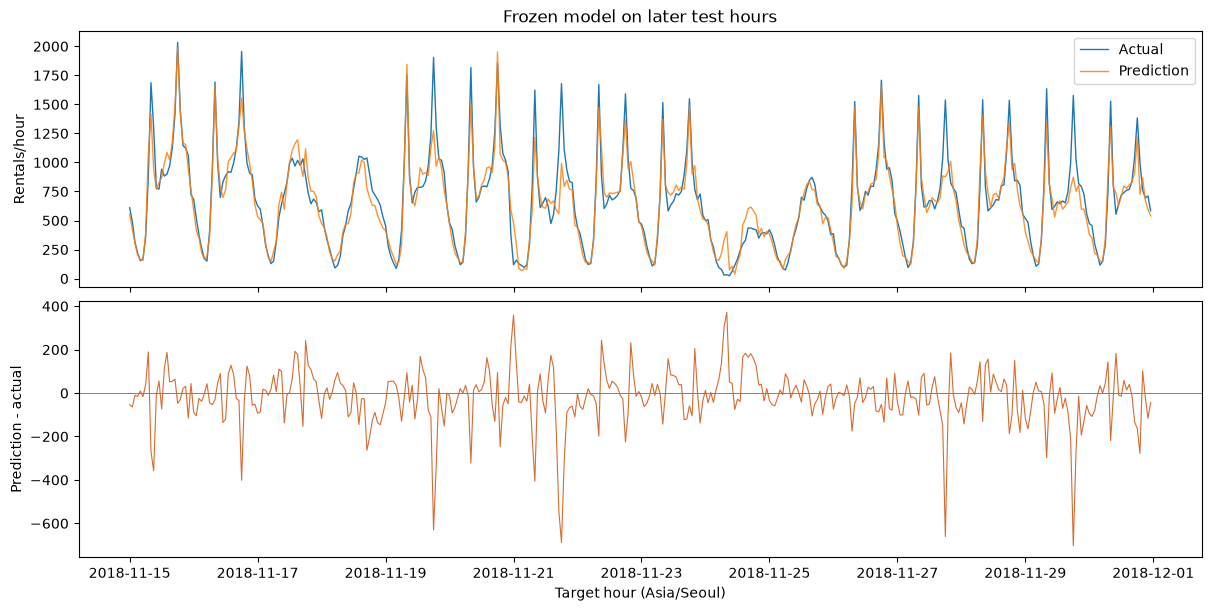

Test errors by day_type


,mae,rmse,bias,hours,dates
weekday,88.81,137.51,-31.13,288.0,12.0
weekend,74.54,102.56,12.95,96.0,4.0


Test errors by rain_positive


,mae,rmse,bias,hours,dates
False,84.88,128.98,-21.21,380.0,16.0
True,120.36,183.14,84.65,4.0,2.0


In [15]:
error = test_predictions["prediction"] - test_predictions["actual"]
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True,
                         constrained_layout=True)
axes[0].plot(test_predictions.index, test_predictions["actual"],
             label="Actual", linewidth=1)
axes[0].plot(test_predictions.index, test_predictions["prediction"],
             label="Prediction", linewidth=1, alpha=0.85)
axes[0].set(title="Frozen model on later test hours", ylabel="Rentals/hour")
axes[0].legend()
axes[1].plot(test_predictions.index, error, color="#d76b31", linewidth=0.8)
axes[1].axhline(0, color="gray", linewidth=0.7)
axes[1].set(ylabel="Prediction - actual", xlabel="Target hour (Asia/Seoul)")
plt.show()
for group in ["day_type", "rain_positive"]:
    grouped = pd.DataFrame(test_diagnostics[group]).T
    print("Test errors by", group)
    display(grouped[["mae", "rmse", "bias", "hours", "dates"]].round(2))

## 10. Keep the complete candidate record

**The following table records every initial and tuned candidate produced during this run.** The phase, settings, validation scores, and selected flag make the comparison traceable. The shared `evaluate()` function generated the predictions, and the plotting cells above calculated charts directly from these in-memory results.

The fitted final model lives in this notebook's kernel. The tuning, feature-importance, and performance charts are also saved under `reports/figures/`. For a one-shot batch rerun and export of the deployable model and standard CSV/JSON reports, run `uv run --locked bike-train`; it uses the same functions and protocol. Notebook execution leaves the existing service artifact and standard experiment reports in place.


In [16]:
display(comparison.sort_values("mae")[[
    "id", "phase", "family", "features", "params",
    "mae", "rmse", "worst_season_ratio", "selected",
]].rename(columns={
    "id": "Candidate", "phase": "Stage", "family": "Model family",
    "features": "Weather group", "params": "Parameters",
    "mae": "Validation MAE", "rmse": "Validation RMSE",
    "worst_season_ratio": "Worst seasonal error / last-week rule",
    "selected": "Selected",
}).reset_index(drop=True))

,Candidate,Stage,Model family,Weather group,Parameters,Validation MAE,Validation RMSE,Worst seasonal error / last-week rule,Selected
0,c17,tuning,boosting,W2,"{""l2_regularization"": 30.0, ""max_leaf_nodes"": 31}",121.317795,207.643053,0.624362,True
1,c16,tuning,boosting,W2,"{""l2_regularization"": 10.0, ""max_leaf_nodes"": 31}",122.422571,210.099328,0.647950,False
2,c15,tuning,boosting,W2,"{""l2_regularization"": 1.0, ""max_leaf_nodes"": 31}",122.546726,209.891119,0.638771,False
3,c13,tuning,boosting,W2,"{""l2_regularization"": 1.0, ""max_leaf_nodes"": 15}",125.539833,211.688529,0.636567,False
4,c08,initial,boosting,W2,"{""l2_regularization"": 10.0, ""max_leaf_nodes"": 15}",126.260567,211.530496,0.633100,False
5,c07,initial,boosting,W1,"{""l2_regularization"": 10.0, ""max_leaf_nodes"": 15}",126.619310,211.492649,0.622190,False
6,c14,tuning,boosting,W2,"{""l2_regularization"": 30.0, ""max_leaf_nodes"": 15}",127.303341,213.251590,0.634470,False
7,c09,initial,boosting,W3,"{""l2_regularization"": 10.0, ""max_leaf_nodes"": 15}",131.554060,217.795925,0.653455,False
8,c21,tuning,forest,W2,"{""max_depth"": 16, ""min_samples_leaf"": 3}",135.204902,241.912566,0.695158,False
9,c18,tuning,forest,W2,"{""max_depth"": 10, ""min_samples_leaf"": 3}",138.847833,244.725882,0.704452,False
